# X1 특집 — 자기정규화 Page CUSUM 을 KODEX 200 실데이터로 해부하다

**R2H 12B 특집** · 069500 KODEX 200 · 2020-01-02 ~ 2025-12-30 · 기준 12번 `c8998a6` · 12B `research/12b_k200_cusum_volatility_alignment`

X1 은 **자기정규화(self-normalized) Page CUSUM** 이다. 자기회귀 모형이 아니라, SVR–GARCH 잔차 e = r/√v^ 를 *그 잔차 자신의 과거 척도* m^ 로 한 번 더 나눈 뒤 Page CUSUM 을 돌린다.

$$\tilde e_t = \frac{e_t}{\sqrt{\hat m_t}},\qquad \hat m_t = \operatorname{mean}\{e_s^2 : s \in [t-252,\ t-61],\ \text{유효}\ \ge 120\}$$

$$S^{\uparrow}_t = \max\{0,\ S^{\uparrow}_{t-1} + \tfrac12[(1-\tfrac1\lambda)\tilde e_t^2 - \ln\lambda]\},\quad \lambda = 2\ (\text{상방}),\ 0.5\ (\text{하방})$$

이 노트북은 X1 하나만 본다: **왜 필요한가 → 분모가 무엇을 기억하나 → 실제 경보 → 11개 급변 구간 → 기준창 민감도 → 합성 검출력 → 시장 반응 → 판정**.

> 관측 귀무 모형이 맞지 않으므로(`NULL_MODEL_INVALID`) 경보·임계값은 서술용 참조다. X1 은 12번에서 결과를 본 뒤 추가된 `EXPLORATORY_EXTENSION` 이고, X1w·민감도 변형은 12B 탐색이다.

### 결론 먼저

| 질문 | 답 |
|---|---|
| X1 이 고치는 것 | 정책 A 잔차의 척도가 1 이 아니다 (연평균 e² 0.95–3.33). Page 상방 증분은 e² > 1.386 이면 양수라 상태가 저절로 쌓인다. X1 은 이 **표류**를 지운다 |
| 실데이터 경보 | 값은 2020-09-21 부터 (유효 120일). 2021–2025 **상방 0회**, 하방 4회(2020-12 ~ 2021-07), 양방향 3회 |
| 왜 상방이 0 인가 | 2021–2025 의 충격은 SVR 예측분산이 이미 반영해 잔차가 작다 (2024-08-05: v^ 5.01, e −4.30, ẽ −3.77) |
| 하방 경보의 정체 | 4회 중 3회가 COVID 의 큰 e² 가 기준창에 들어 있던 기간(2020-05-12 ~ 2021-05-07)이다. 정상으로 돌아온 잔차가 커진 분모 때문에 작아 보였다. 마지막 1회(2021-07-01)는 2020 하반기 고변동이 남은 기간 (m^ 1.48) — 분모의 기억 |
| 합성 검출력 | 하루 극단 충격 S08 에서 상방 0.640 (원래 0.325). 지속형 분산 변화는 둘 다 오경보 수준 |
| 오경보율 | α=0.05 홀드아웃 6.6% — 경로 군집 구간 기준 `CALIBRATION_FAIL` |
| 시장 정보 | 원래 Page 상방과 ρ −0.25 (다른 정보). 수준 ρ 0.58 → 0.26. 미래 변동성 증분: 양방향 +8.1% (공통일 +2.7%), 하방 +3.8% (공통일 +4.5%), 상방 −1.1% |
| 판정 | **경보 정책으로는 채택하지 않는다.** 하방·양방향 상태를 AE 연속 피처 후보로, 2026 이후 자료·다른 ETF 사전 등록 검증 뒤에만 쓴다 |

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t22_k200_overlay_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import contextlib  # 단계 출력 가두기
import hashlib  # 파일 지문
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import importlib.util  # 단계 스크립트 불러오기
import io  # 출력 버퍼
import json  # 설정·캡션
import platform  # Python 버전
import time  # 단계 소요 시간

import matplotlib  # 그림 백엔드
matplotlib.use("Agg")  # 화면 없이 파일로 저장
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, Markdown, display  # 표·그림·문단 출력
import matplotlib.pyplot as plt  # 그림 기본 설정
from matplotlib import font_manager  # 한글 글꼴 등록

FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(FONT_FILE)).get_name()  # 한글 글꼴 사용
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

# 12번과 같은 고정 환경 (user-site 차단 포함).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2", "scikit-learn": "1.9.1"}  # 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), **{k: metadata.version(k) for k in ("numpy", "pandas", "scipy", "matplotlib", "scikit-learn")}}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패
assert ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
pd.set_option("display.width", 220)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화
pd.set_option("display.max_rows", 60)  # 행 생략 완화

from r2h.k200_overlay import figures as G  # 12B 그림 (대표 쌍·라벨)

assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
BASE = ROOT / "research/k200_cusum_overlay_12b"  # 12B 산출물 폴더
RES = BASE / "results"  # 결과표
FIGDIR = BASE / "figures"  # 그림 (PNG 320dpi + SVG)
OUT = ROOT / "outputs/t22"  # 일별 장형 Parquet (Git 제외)


def sha(p):  # 파일 SHA256
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()  # 바이트 단위 지문


def preview(path, width=1100):  # 노트북 용량을 줄이는 축소 미리보기 (원본은 figures/)
    from PIL import Image as PILImage  # 이미지 축소
    im = PILImage.open(path)  # 320dpi 원본
    im.thumbnail((width, width * 3))  # 가로 1100px 이하로 축소
    buf = io.BytesIO()  # 출력 버퍼
    im.save(buf, format="PNG", optimize=True)  # PNG 로 다시 저장
    return buf.getvalue()  # 바이트 반환


# 계약 동결 지문: 국면·이벤트 정의는 계산 전에 커밋한 그대로여야 한다.
FREEZE = dict(reversed(line.split(maxsplit=1)) for line in (BASE / "CONTRACT_FREEZE_SHA256.txt").read_text().splitlines())  # 경로 → 해시
assert all(sha(ROOT / p) == h for p, h in FREEZE.items()), "12B-lock-1 계약 파일 변경"  # 동결본과 같아야 한다
# 12번 기준 커밋 c8998a6 의 추적 파일 915개 지문 — 실행 전후 모두 같아야 한다 (G0).
PROT = [line.split(maxsplit=1) for line in (BASE / "evidence/PROTECTED_12_SHA256.txt").read_text().splitlines()]  # (해시, 경로)
bad = [p for h, p in PROT if sha(ROOT / p) != h]  # 바뀐 보호 파일
assert not bad, f"보호 파일 변경: {bad[:5]}"  # 12번 산출물은 읽기만
INPUTS = [line.split(maxsplit=1) for line in (BASE / "evidence/INPUT_SHA256.txt").read_text().splitlines()]  # 동결 입력 (Feature Store·귀무표·원자료)
bad_in = [p for h, p in INPUTS if sha(ROOT / p) != h]  # 바뀐 입력
assert not bad_in, f"동결 입력 변경: {bad_in}"  # 12번 Feature Store 를 그대로 써야 한다
print("작업트리:", ROOT, "| 12번 보호", len(PROT), "개 · 입력", len(INPUTS), "개 불변 | 환경", ACTUAL_ENV)  # 검증 요약

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1019/R2H_K200_CUSUM_12 | 12번 보호 915 개 · 입력 14 개 불변 | 환경 {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1'}


In [2]:
# 12B 계산 전부를 이 커널에서 다시 실행한다: 정렬 → 국면 → X1 → OFAT·합의 → 국면 반응 → 증분 정보 → 압축 → 그림.
# SVR 재학습·Monte Carlo 는 없다 (X1w 용 fit 0 표본내 잔차 1회 재계산만, model_hash 대조).
T = {p.name: pd.read_csv(p) for p in sorted(RES.glob('*.csv*'))}  # 결과표 전부 (계산은 다시 하지 않음)
T_EVT = T['x1_event_table.csv'].query('event_set=="A_t20"')  # 사건별 X1 표

In [3]:
# X1 해부에 쓰는 동결 자료 — 12B 정렬 원장·X1 일별표·시장 마스터·12번 합성·홀드아웃 결과.
from r2h.k200_controlled import core as C  # 12번 Page·자기정규화 함수 (읽기 전용)
from r2h.k200_overlay import x1 as X  # 12B X1 해부 함수 (분모 m^)
import matplotlib.dates as mdates  # 날짜 축

FX = BASE / "figures_x1"  # 특집 그림 저장 폴더
FX.mkdir(exist_ok=True)  # 없으면 만든다
plt.rcParams["svg.hashsalt"] = "t22_x1_feature"  # SVG 내부 id 결정적 고정
X1D = pd.read_parquet(OUT / "x1_real_daily.parquet")  # X1 일별 해부표 (CSV 는 마지막 비트가 바뀔 수 있어 Parquet)
MA = pd.read_parquet(OUT / "market_daily_master.parquet")  # 시장 마스터 1,473일
CHK = json.loads((BASE / "evidence/x1_checks.json").read_text(encoding="utf-8"))  # 원장 재계산·fit 0 검사
CRIT = CHK["crit"]  # N1 보정 임계값 (α 0.05·0.20)
EV = pd.read_csv(RES / "events_table.csv", parse_dates=["start", "end"])  # 11번 급변 구간 + 확대 시작점
EVA = EV[EV["event_set"] == "A_t20"].reset_index(drop=True)  # CUSUM 과 독립 정의된 11개 구간
R12 = ROOT / "research/k200_cusum_controlled_12/results"  # 12번 결과 폴더
SYN = pd.read_csv(R12 / "synthetic_size_power.csv")  # 합성 13 시나리오 검출률
HOLD = pd.read_csv(R12 / "size_holdout.csv")  # 홀드아웃 오경보율
d = X1D["date"]  # 날짜축
e = X1D["e_B1"].to_numpy()  # B1 표준화 잔차 e = r/√v^
hu, hd = CRIT["page_up"]["0.05"], CRIT["page_down"]["0.05"]  # 원래 Page 상·하방 h
su, sd = CRIT["page_up_sn"]["0.05"], CRIT["page_down_sn"]["0.05"]  # X1 상·하방 h
SAVED = []  # 저장한 그림 이름


def show(fig, name):  # 그림을 저장(PNG 200dpi)하고 노트북에 표시
    fig.savefig(FX / f"{name}.png", dpi=200, bbox_inches="tight", metadata={"Software": None})  # 결정적 PNG
    buf = io.BytesIO()  # 표시용 버퍼
    fig.savefig(buf, format="png", dpi=100, bbox_inches="tight")  # 노트북 용량을 줄인 해상도
    plt.close(fig)  # 메모리 해제
    SAVED.append(name)  # 기록
    display(Image(data=buf.getvalue()))  # 표시


def shade(ax, alpha=0.10):  # 11번 급변 구간 음영
    for a, b in zip(EVA["start"], EVA["end"]):  # 구간마다
        ax.axvspan(a, b + pd.Timedelta(days=1), color="#e34948", alpha=alpha, lw=0, zorder=0)  # 붉은 음영


# 재계산 검사: 저장된 B1 잔차에서 X1 을 다시 만들면 원장 상태와 같아야 한다 (재적합 없음).
sn = C.selfnorm(e)  # e~ = e/√m^
up_free, _ = C.page_free(sn, 2.0)  # X1 상방 자유 상태
dn_free, _ = C.page_free(sn, 0.5)  # X1 하방 자유 상태
assert np.array_equal(up_free, X1D["X1_up"].to_numpy(), equal_nan=True)  # 상방 비트 동일
assert np.array_equal(dn_free, X1D["X1_down"].to_numpy(), equal_nan=True)  # 하방 비트 동일
print("X1 재계산 = 원장 · fit 0 model_hash", CHK["fit0_model_hash"], "· 첫 유효일", CHK["x1_first_valid"], "· NA", CHK["x1_na_days"], "일")  # 요약

X1 재계산 = 원장 · fit 0 model_hash 92a29bcd08ac7f81 · 첫 유효일 2020-09-21 · NA 180 일


## 1. 왜 X1 인가 — 잔차 척도와 Page 의 표류

Page 상방 증분은 ½[(1 − 1/λ)e² − ln λ] 이다. λ = 2 이면 **e² > 2 ln 2 ≈ 1.386** 일 때 양수다. 귀무에서 E[e²] = 1 이면 증분 평균이 음수라 상태가 0 근처에 머물지만,
SVR 정책 A 잔차는 연평균 e² 가 2020 3.33, 2024 1.46, 2025 1.57 로 경계를 넘는 해가 있다. 그런 해에는 충격이 없어도 상태가 쌓인다.
X1 은 과거 척도 m^ 로 나눠 ẽ² 의 평균을 1 근처로 되돌린다.

,연평균 e²,연평균 e~²,증분>0 비율 (e),증분>0 비율 (e~),연 증분 합 (e),연 증분 합 (e~)
2020,3.329,0.384,0.415,0.059,120.451,-17.042
2021,0.949,0.585,0.242,0.117,-27.141,-49.656
2022,1.297,1.244,0.317,0.293,-5.477,-8.740
2023,1.097,0.911,0.261,0.233,-17.721,-29.116
2024,1.462,1.202,0.266,0.242,4.648,-11.220
2025,1.573,1.013,0.289,0.207,11.276,-22.556


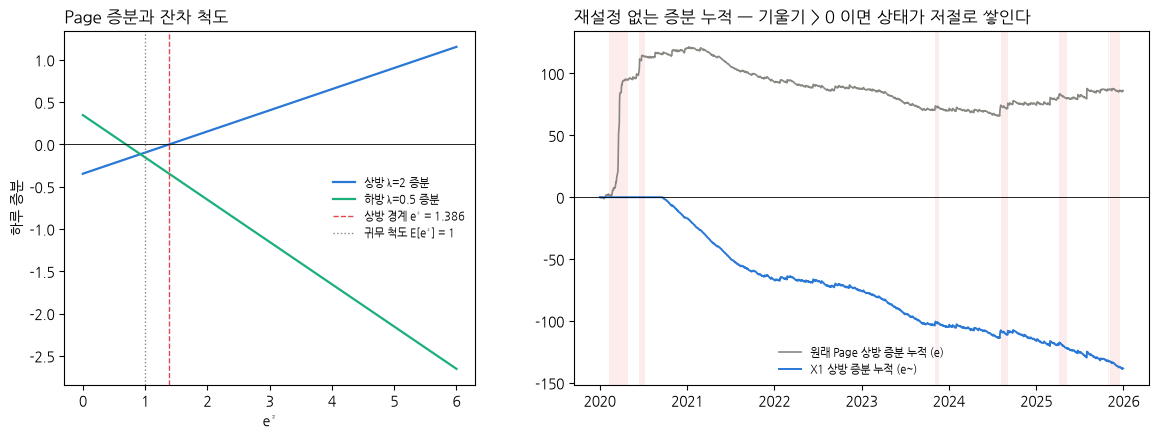

In [4]:
# 그림 X01 — 왜 X1 인가: Page 상방 증분 0.5((1-1/λ)e² - ln λ) 는 e² > 2 ln2 ≈ 1.386 이면 양수다. 잔차 척도가 1 보다 크면 상태가 표류한다.
lam = 2.0  # 상방 분산비
thr = np.log(lam) / (1 - 1 / lam)  # 증분이 0 이 되는 e² 경계 (= 2 ln2)
yr = d.dt.year  # 연도
inc_e = C.page_increment(e, lam)  # 원래 Page 상방 하루 증분
inc_s = C.page_increment(sn, lam)  # X1 상방 하루 증분 (NA 유지)
tab = pd.DataFrame(index=sorted(yr.unique()))  # 연도별 표
tab["연평균 e²"] = pd.Series(e**2).groupby(yr.values).mean()  # 원래 잔차 척도
tab["연평균 e~²"] = pd.Series(sn**2).groupby(yr.values).mean()  # X1 잔차 척도
tab["증분>0 비율 (e)"] = pd.Series(inc_e > 0).groupby(yr.values).mean()  # 원래 상방 양의 증분 비율
tab["증분>0 비율 (e~)"] = pd.Series(np.where(np.isfinite(inc_s), inc_s > 0, np.nan)).groupby(yr.values).mean()  # X1 상방 (NA 제외)
tab["연 증분 합 (e)"] = pd.Series(inc_e).groupby(yr.values).sum()  # 원래 연간 누적 표류
tab["연 증분 합 (e~)"] = pd.Series(inc_s).groupby(yr.values).sum(min_count=1)  # X1 연간 누적
display(tab.round(3))  # 표 출력
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})  # 두 패널
xs = np.linspace(0, 6, 300)  # e² 격자
ax[0].plot(xs, 0.5 * ((1 - 1 / lam) * xs - np.log(lam)), color="#2a78d6", lw=1.6, label="상방 λ=2 증분")  # 증분 직선
ax[0].plot(xs, 0.5 * ((1 - 1 / 0.5) * xs - np.log(0.5)), color="#1baf7a", lw=1.6, label="하방 λ=0.5 증분")  # 하방 증분
ax[0].axhline(0, color="k", lw=0.6)  # 0 선
ax[0].axvline(thr, color="#e34948", lw=1, ls="--", label=f"상방 경계 e² = {thr:.3f}")  # 경계
ax[0].axvline(1, color="#898781", lw=1, ls=":", label="귀무 척도 E[e²] = 1")  # 이상적 척도
ax[0].set_xlabel("e²")  # 축 이름
ax[0].set_ylabel("하루 증분")  # 축 이름
ax[0].legend(fontsize=8, frameon=False)  # 범례
ax[0].set_title("Page 증분과 잔차 척도", loc="left")  # 제목
c_e = np.nancumsum(inc_e)  # 원래 상방 증분 누적 (재설정 없이)
c_s = np.nancumsum(np.nan_to_num(inc_s, nan=0.0))  # X1 상방 증분 누적
ax[1].plot(d, c_e, color="#898781", lw=1.2, label="원래 Page 상방 증분 누적 (e)")  # 표류
ax[1].plot(d, c_s, color="#2a78d6", lw=1.4, label="X1 상방 증분 누적 (e~)")  # 표류 제거
ax[1].axhline(0, color="k", lw=0.6)  # 0 선
shade(ax[1])  # 사건 음영
ax[1].set_title("재설정 없는 증분 누적 — 기울기 > 0 이면 상태가 저절로 쌓인다", loc="left")  # 제목
ax[1].legend(fontsize=8, frameon=False)  # 범례
show(fig, "X01_증분과_척도표류")  # 저장·표시

## 2. 분모 m^ 가 기억하는 것

m^_t 는 **61 ~ 252 거래일 전**의 잔차 척도다. 최근 60일을 빼는 이유는 지금 진행 중인 변화가 분모로 바로 흡수되지 않게 하려는 것이다.
대가는 두 가지다. (1) 평가 구간 잔차만 쓰면 유효 120일이 2020-09-21 에야 차서 COVID 를 보지 못한다. (2) 큰 충격이 기준창에 들어와 있는 동안은 분모가 커서, 정상으로 돌아온 잔차가 '감소' 로 보인다.
COVID 구간(2020-02-11 ~ 04-29)이 기준창 안에 있던 기간은 2020-05-12 ~ 2021-05-07 이다. X1 하방 경보 4회 중 3회(2020-12-03, 2021-02-19, 2021-04-19)가 이 기간에 있고, 마지막 2021-07-01 은 그 뒤 2020 하반기의 높은 잔차가 아직 기준창에 남은 때다.

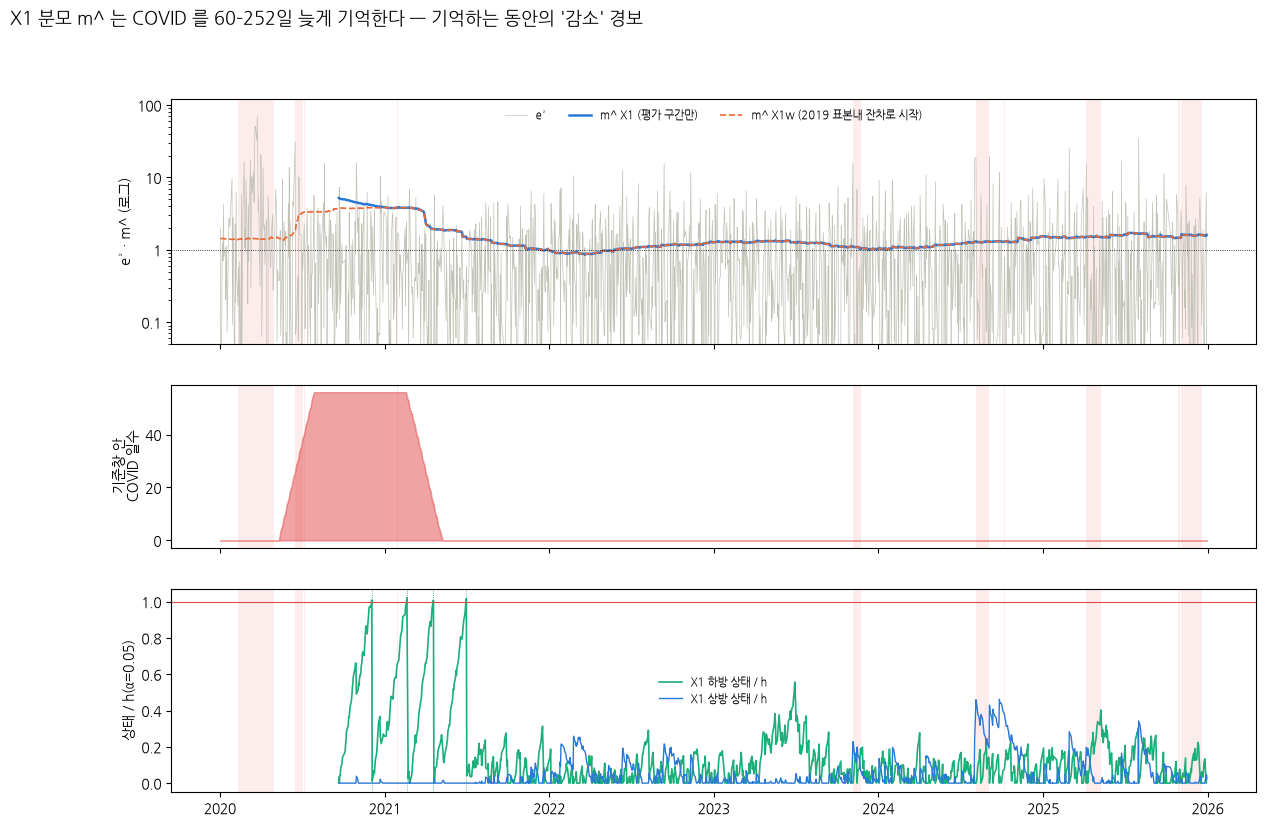

COVID 가 기준창 안에 있는 기간: 2020-05-12 ~ 2021-05-07 · X1 하방 경보: ['2020-12-03', '2021-02-19', '2021-04-19', '2021-07-01']


In [5]:
# 그림 X02 — 분모 m^ 의 기억: 기준창 [t-252, t-61] 안에 COVID 급락기(2020-02-11 ~ 04-29)가 며칠 들어 있는가와 m^ 의 관계.
cv = ((d >= "2020-02-11") & (d <= "2020-04-29")).to_numpy().astype(int)  # COVID 구간 표시 (평가 구간 위치)
cs = np.r_[0, np.cumsum(cv)]  # 누적합
t = np.arange(len(d))  # 위치
inwin = cs[np.clip(t - 61 + 1, 0, len(d))] - cs[np.clip(t - 252, 0, len(d))]  # 기준창 안 COVID 일수
fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [1.2, 0.8, 1]})  # 세 패널
ax[0].plot(d, X1D["e2_B1"], color="#c3c2b7", lw=0.5, label="e²")  # 일별 e²
ax[0].plot(d, X1D["m_hat_X1"], color="#2a78d6", lw=1.8, label="m^ X1 (평가 구간만)")  # X1 분모
ax[0].plot(d, X1D["m_hat_X1w"], color="#eb6834", lw=1.2, ls="--", label="m^ X1w (2019 표본내 잔차로 시작)")  # X1w 분모
ax[0].axhline(1, color="k", lw=0.6, ls=":")  # 이상적 척도
ax[0].set_yscale("log")  # 로그 축
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))  # 일반 숫자 눈금
ax[0].yaxis.set_minor_formatter(plt.NullFormatter())  # 보조 눈금 글자 없음
ax[0].set_ylim(0.05, 120)  # 범위
ax[0].legend(fontsize=8, frameon=False, ncol=3)  # 범례
ax[0].set_ylabel("e² · m^ (로그)")  # 축 이름
ax[1].fill_between(d, 0, inwin, color="#e34948", alpha=0.5, step="mid")  # 기준창 안 COVID 일수
ax[1].set_ylabel("기준창 안\nCOVID 일수")  # 축 이름
ax[2].plot(d, X1D["X1_down_path_a05"] / sd, color="#1baf7a", lw=1.2, label="X1 하방 상태 / h")  # 하방 상태
ax[2].plot(d, X1D["X1_up_path_a05"] / su, color="#2a78d6", lw=1.0, label="X1 상방 상태 / h")  # 상방 상태
ax[2].axhline(1, color="#e34948", lw=0.8)  # 임계값
for dd in X1D.loc[X1D["X1_down_alarm_a05"].astype(bool), "date"]:  # 하방 경보일
    ax[2].axvline(dd, color="#1baf7a", lw=0.6, ls=":")  # 점선
ax[2].legend(fontsize=8, frameon=False)  # 범례
ax[2].set_ylabel("상태 / h(α=0.05)")  # 축 이름
for a in ax:  # 패널마다
    shade(a)  # 사건 음영
ax[2].xaxis.set_major_locator(mdates.YearLocator())  # 연 눈금
fig.suptitle("X1 분모 m^ 는 COVID 를 60–252일 늦게 기억한다 — 기억하는 동안의 '감소' 경보", x=0.01, ha="left", fontsize=13)  # 제목
show(fig, "X02_분모의_기억")  # 저장·표시
first_in, last_in = d[inwin > 0].iloc[0].date(), d[inwin > 0].iloc[-1].date()  # COVID 가 기준창에 머문 기간
print("COVID 가 기준창 안에 있는 기간:", first_in, "~", last_in, "· X1 하방 경보:", [str(x.date()) for x in X1D.loc[X1D["X1_down_alarm_a05"].astype(bool), "date"]])  # 경보와의 관계

## 3. 경보 일지 — 언제, 어떤 시장에서 울렸나

In [6]:
# 경보 일지 — 각 계열의 α=0.05 경보일과 그날 시장 맥락 (수익률 · 연환산 20일 · v^ · e · e~ · m^).
cols = dict(E3_up_alarm_a05="Page 상방", E3_down_alarm_a05="Page 하방", E3_two_alarm_a05="Page 양방향", X1_up_alarm_a05="X1 상방", X1_down_alarm_a05="X1 하방")  # 계열 이름
cols.update(X1_two_alarm_a05="X1 양방향", X1w_up_alarm_a05_REFERENCE="X1w 상방(참조)", X1w_down_alarm_a05_REFERENCE="X1w 하방(참조)", X1w_two_alarm_a05_REFERENCE="X1w 양방향(참조)")  # 참조 계열
log = []  # 일지 행
for c, lab in cols.items():  # 계열마다
    for i in np.flatnonzero(X1D[c].astype(bool).to_numpy()):  # 경보 위치
        r = X1D.iloc[i]  # 그날 값
        row = {"계열": lab, "날짜": r["date"].date(), "수익률%": r["daily_log_return_pct"], "연환산20": r["annualized_vol_20"], "v^": r["predicted_variance_B1"]}  # 시장 맥락
        row.update({"e": r["e_B1"], "e~ (X1)": r["e_sn_X1"], "m^ X1": r["m_hat_X1"], "m^ X1w": r["m_hat_X1w"]})  # 잔차·분모
        log.append(row)  # 일지에 추가
LOG = pd.DataFrame(log)  # 표
display(LOG.round(3))  # 출력
display(LOG.groupby("계열").size().rename("경보일").to_frame().T)  # 계열별 수

,계열,날짜,수익률%,연환산20,v^,e,e~ (X1),m^ X1,m^ X1w
0,Page 상방,2020-03-23,-6.059,53.922,1.127,-5.706,NaN,NaN,1.416
1,Page 상방,2020-08-20,-3.939,22.109,1.000,-3.939,NaN,NaN,3.375
2,Page 하방,2021-06-30,0.350,8.994,0.579,0.460,0.372,1.530,1.530
3,Page 양방향,2020-03-24,8.876,65.079,1.127,8.360,NaN,NaN,1.416
4,X1 하방,2020-12-03,0.705,15.511,1.366,0.603,0.296,4.141,3.831
5,X1 하방,2021-02-19,0.868,24.642,1.161,0.806,0.413,3.811,3.811
6,X1 하방,2021-04-19,-0.013,9.430,0.647,-0.016,-0.011,1.946,1.946
7,X1 하방,2021-07-01,-0.577,8.751,0.573,-0.763,-0.628,1.477,1.477
8,X1 양방향,2020-12-21,0.130,16.622,0.255,0.257,0.130,3.936,3.789
9,X1 양방향,2021-03-29,-0.179,14.721,0.669,-0.219,-0.120,3.321,3.321


계열,Page 상방,Page 양방향,Page 하방,X1 양방향,X1 하방,X1w 상방(참조),X1w 양방향(참조),X1w 하방(참조)
경보일,2,1,1,3,4,4,5,4


## 4. 11개 급변 구간 확대

11번 급변 구간(CUSUM 과 독립 정의)마다 시작 −20일 ~ 끝 +40일을 확대했다. 2020 의 4개 구간은 X1 값이 없어 X1w(2019 표본내 잔차로 기준을 채운 참조)만 그려진다.
2021–2025 7개 구간에서 X1 상방 상태/h 최대는 0.46 (2024-08) 이다.

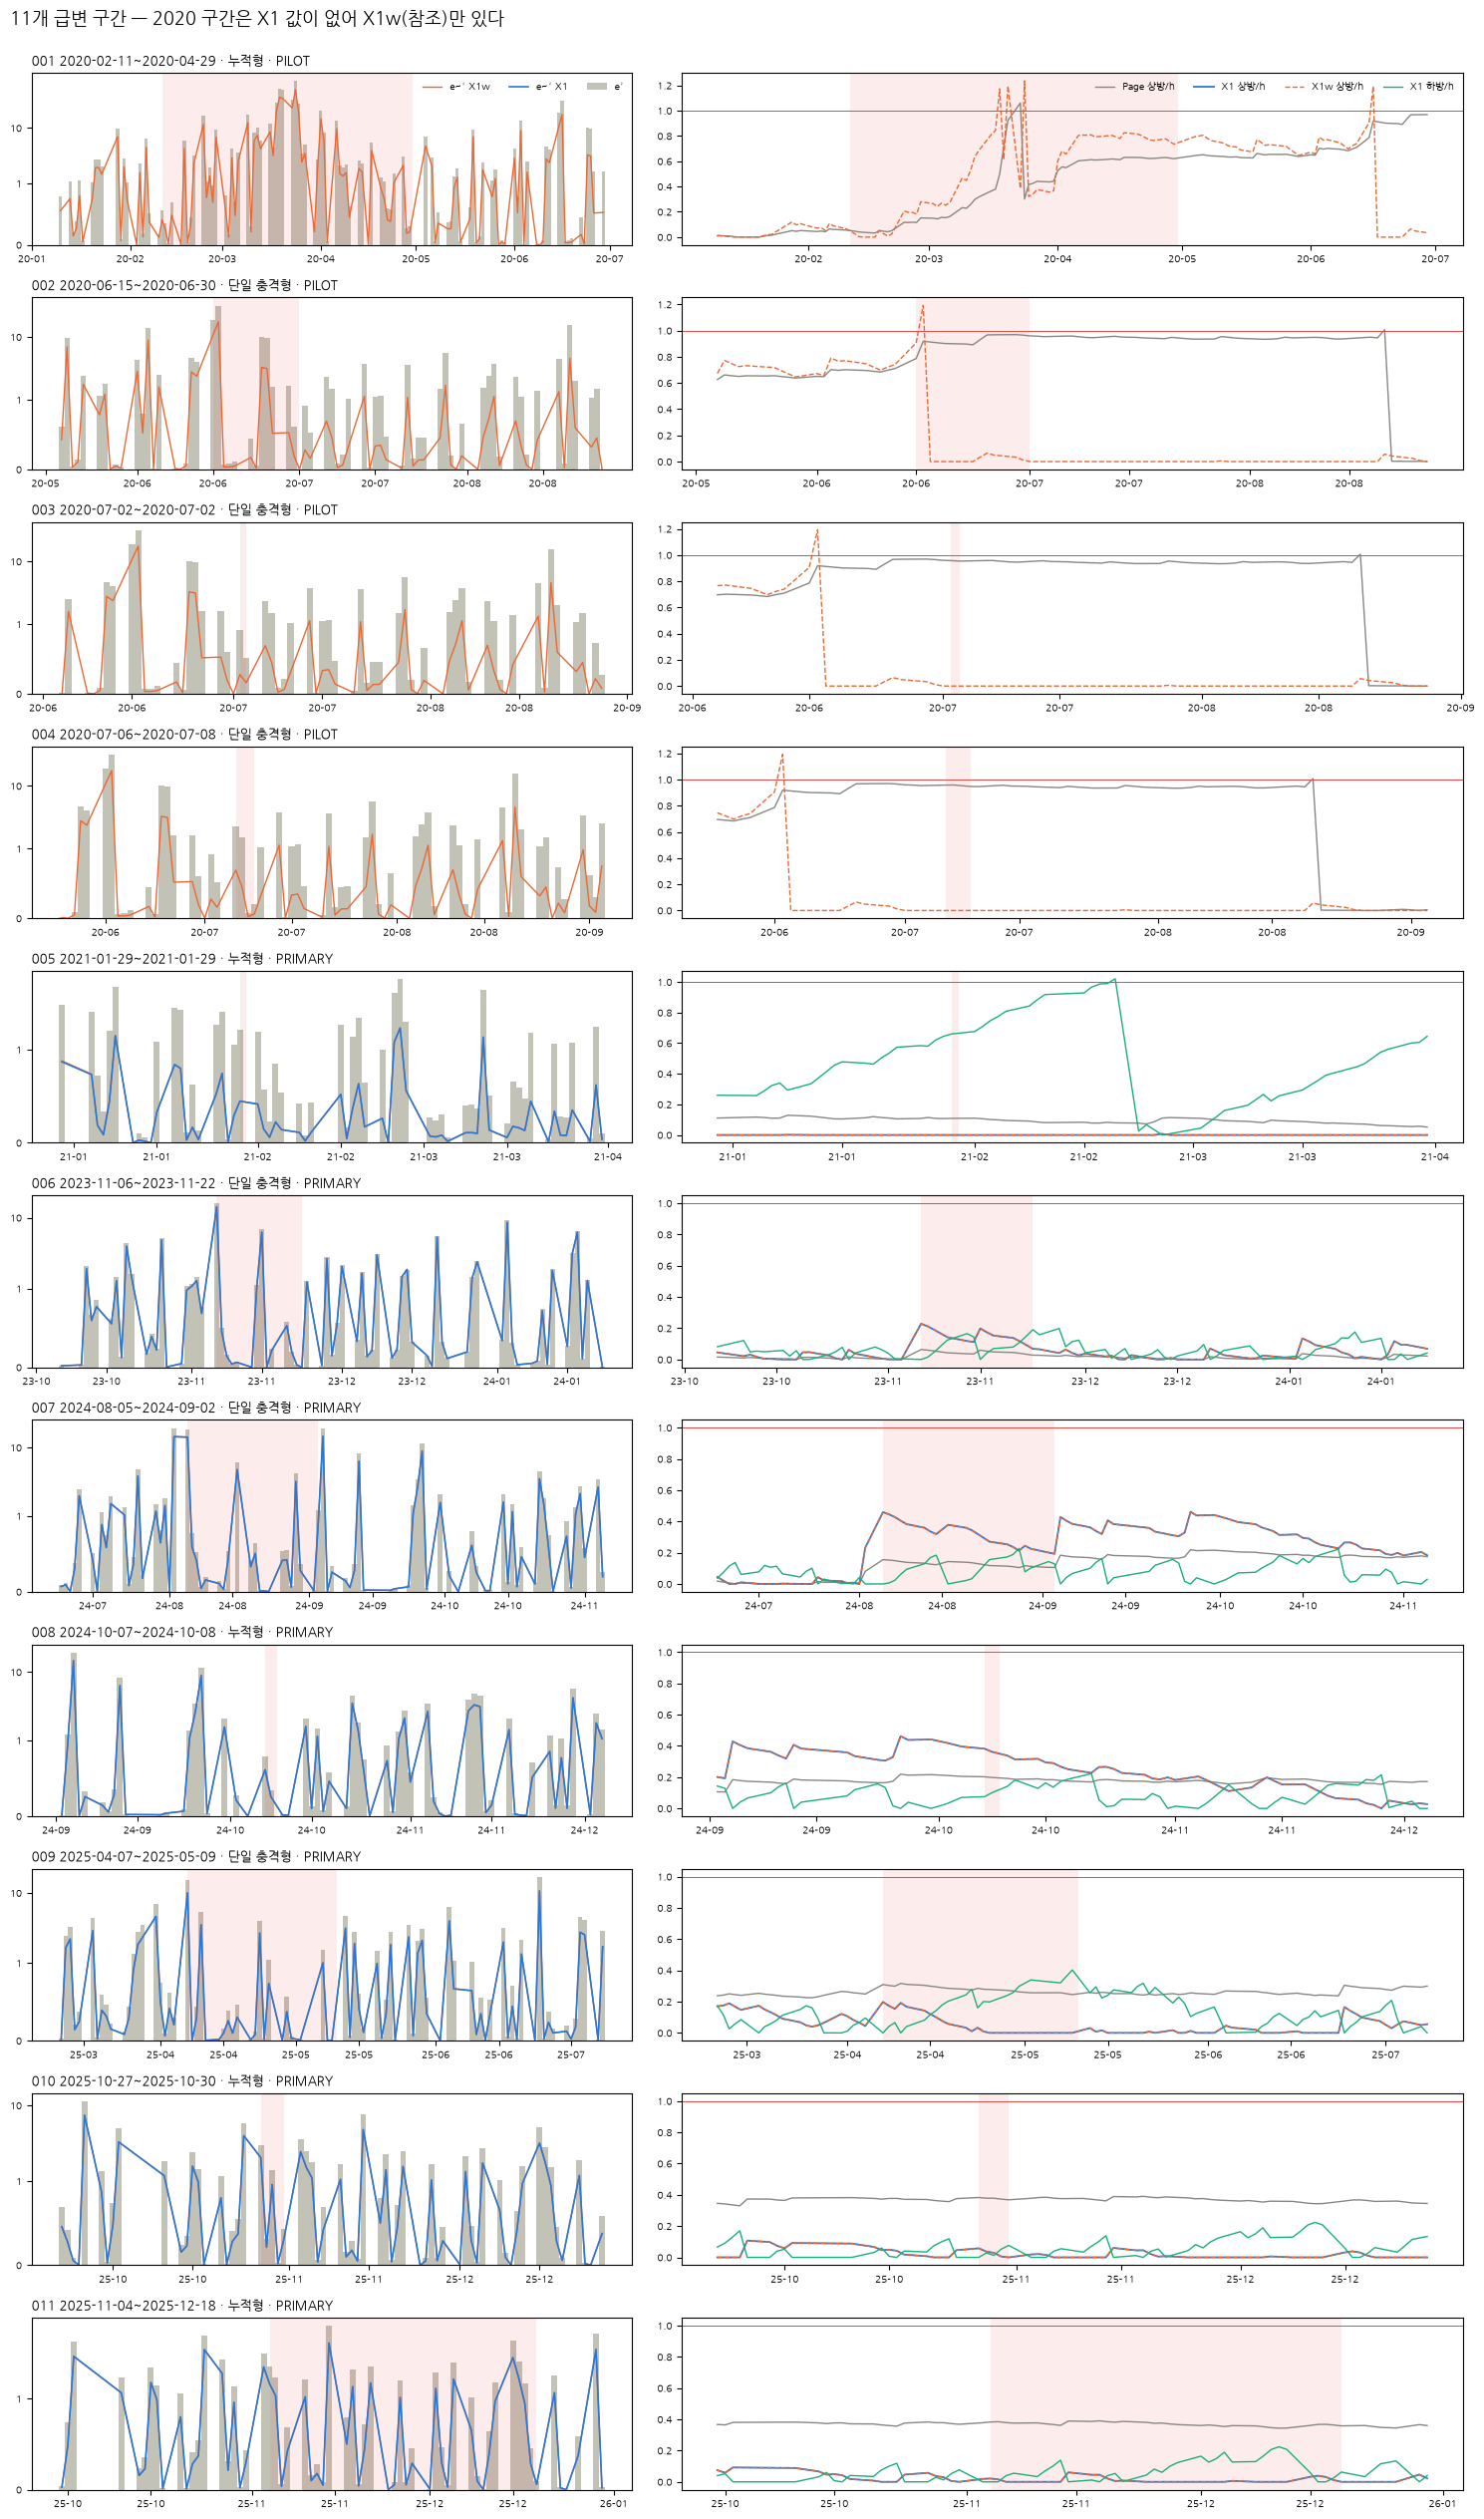

,interval_id,shock_type,period,E3_up_path_max_over_h,X1_up_path_max_over_h,X1w_up_path_max_over_h,X1_down_path_max_over_h,X1_valid_share
0,069500_q20_001,누적형,PILOT,1.06,NaN,1.24,NaN,0.0
1,069500_q20_002,단일 충격형,PILOT,0.97,NaN,1.19,NaN,0.0
2,069500_q20_003,단일 충격형,PILOT,0.96,NaN,0.01,NaN,0.0
3,069500_q20_004,단일 충격형,PILOT,0.96,NaN,0.01,NaN,0.0
4,069500_q20_005,누적형,PRIMARY,0.11,0.01,0.01,1.02,1.0
5,069500_q20_006,단일 충격형,PRIMARY,0.06,0.23,0.23,0.20,1.0
6,069500_q20_007,단일 충격형,PRIMARY,0.22,0.46,0.46,0.23,1.0
7,069500_q20_008,누적형,PRIMARY,0.20,0.38,0.38,0.22,1.0
8,069500_q20_009,단일 충격형,PRIMARY,0.32,0.20,0.20,0.40,1.0
9,069500_q20_010,누적형,PRIMARY,0.39,0.06,0.06,0.14,1.0


In [7]:
# 그림 X03 — 11개 급변 구간 확대: 구간 시작 -20일 ~ 끝 +40일의 e² 와 e~², 상방·하방 상태/h (원래 Page · X1 · X1w).
n = len(EVA)  # 사건 수
fig, ax = plt.subplots(n, 2, figsize=(15, 2.3 * n), gridspec_kw={"width_ratios": [1, 1.3]})  # 사건 × 두 패널
for k, ev in EVA.iterrows():  # 사건마다
    a, b = max(int(ev["i_start"]) - 20, 0), min(int(ev["i_end"]) + 40, len(d) - 1)  # 창 위치
    w = X1D.iloc[a : b + 1]  # 사건 창
    ax[k, 0].bar(w["date"], w["e2_B1"], color="#c3c2b7", width=1, label="e²")  # 원래 잔차 제곱
    ax[k, 0].plot(w["date"], w["e_sn_X1w"] ** 2, color="#eb6834", lw=1, label="e~² X1w")  # X1w 정규화 잔차²
    ax[k, 0].plot(w["date"], w["e_sn_X1"] ** 2, color="#2a78d6", lw=1.2, label="e~² X1")  # X1 정규화 잔차²
    ax[k, 0].set_yscale("symlog", linthresh=1)  # 0 근처 선형·큰 값 로그
    ax[k, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))  # 일반 숫자 눈금
    ax[k, 0].set_title(f"{ev['interval_id'][-3:]} {ev['start'].date()}~{ev['end'].date()} · {ev['shock_type']} · {ev['period']}", loc="left", fontsize=9)  # 사건 이름
    ax[k, 1].plot(w["date"], w["E3_up_path_a05"] / hu, color="#898781", lw=1, label="Page 상방/h")  # 원래 상방
    ax[k, 1].plot(w["date"], w["X1_up_path_a05"] / su, color="#2a78d6", lw=1.3, label="X1 상방/h")  # X1 상방
    ax[k, 1].plot(w["date"], w["X1w_up_path_a05_REFERENCE"] / su, color="#eb6834", lw=1, ls="--", label="X1w 상방/h")  # X1w 상방
    ax[k, 1].plot(w["date"], w["X1_down_path_a05"] / sd, color="#1baf7a", lw=1, label="X1 하방/h")  # X1 하방
    ax[k, 1].axhline(1, color="#e34948", lw=0.7)  # 임계값
    for z in ax[k]:  # 두 패널
        z.axvspan(ev["start"], ev["end"] + pd.Timedelta(days=1), color="#e34948", alpha=0.10, lw=0)  # 구간 음영
        z.xaxis.set_major_formatter(mdates.DateFormatter("%y-%m"))  # 날짜 형식
        z.tick_params(labelsize=7)  # 눈금 글자
ax[0, 0].legend(fontsize=7, frameon=False, ncol=3)  # 범례
ax[0, 1].legend(fontsize=7, frameon=False, ncol=4)  # 범례
plt.tight_layout(rect=(0, 0, 1, 0.985))  # 제목 자리를 남기고 여백 정리
fig.suptitle("11개 급변 구간 — 2020 구간은 X1 값이 없어 X1w(참조)만 있다", x=0.01, y=0.997, ha="left", fontsize=13)  # 제목
show(fig, "X03_급변구간11_확대")  # 저장·표시
display(T_EVT[["interval_id", "shock_type", "period", "E3_up_path_max_over_h", "X1_up_path_max_over_h", "X1w_up_path_max_over_h", "X1_down_path_max_over_h", "X1_valid_share"]].round(2))  # 사건별 최대 비율

## 5. 기준창 민감도 (탐색)

기준창 위치·길이·최소 유효일을 바꾼 네 변형의 **원시 상태**만 비교한다. 변형마다 임계값을 보정하지 않았으므로 경보는 그리지 않는다.
- 첫 유효일: 짧은 기억 [t−126, t−21]·최소 60일이 2020-04-28 로 가장 이르다 — COVID 후반을 일부 본다. 지연 없음은 2020-06-26, 기본·긴 기억은 2020-09-21.
- 하방 상태 크기(2021–2025 최대): 짧은 기억 17 · 기본 35 · 지연 없음 39 · 긴 기억 60. 기준창이 길수록 과거 고변동을 오래 기억해 '감소' 쪽 상태가 커진다.
- 2024-08-05 충격일의 ẽ 는 네 변형 모두 −3.75 ~ −3.91 로 거의 같다. 그날 X1 이 약했던 것은 기준창이 아니라 SVR 예측분산(v^ 5.01)이 이미 충격을 반영했기 때문이다.

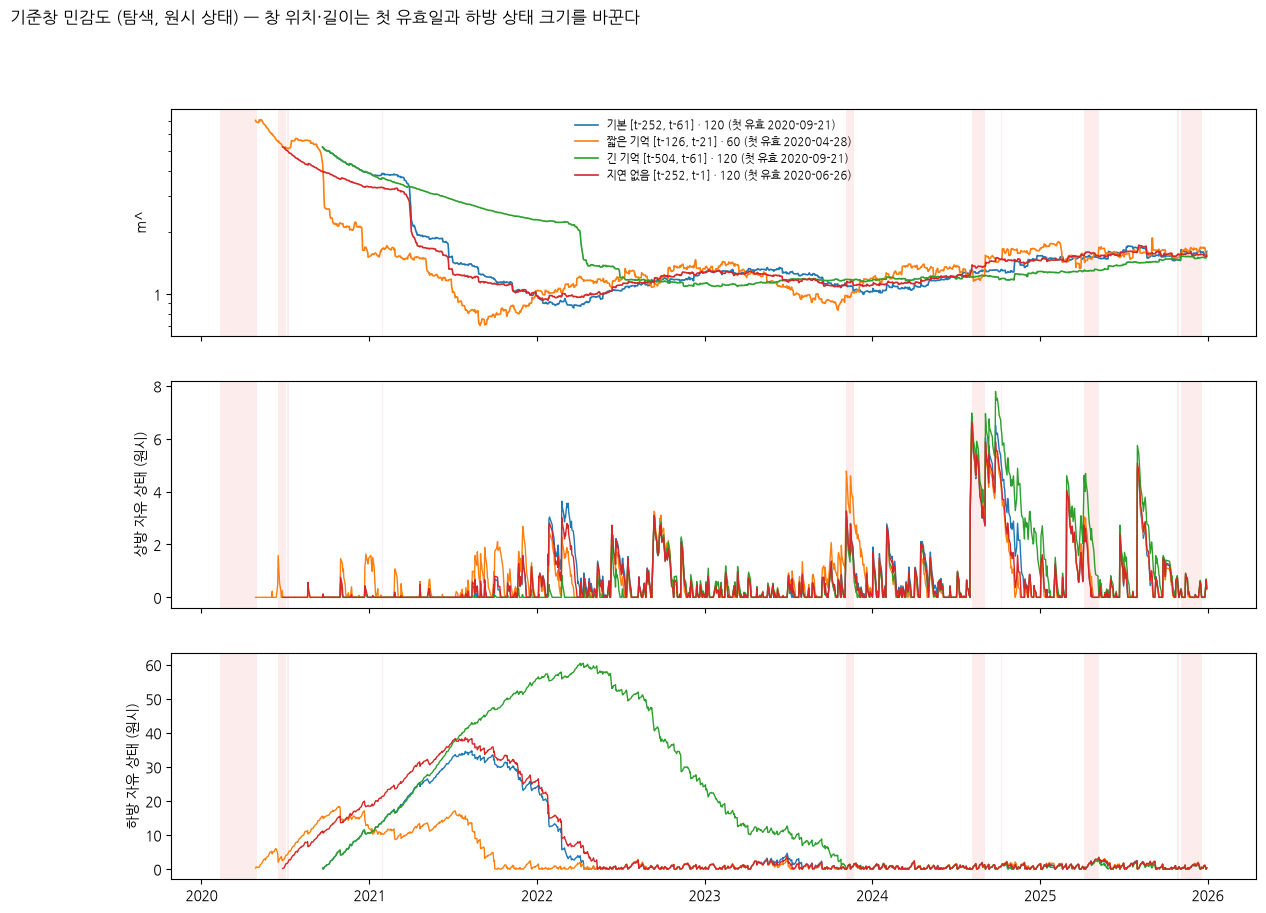

,첫 유효일,평균 m^,상방 상태 2021–25 최대,하방 상태 2021–25 최대,2024-08-05 e~
"기본 [t-252, t-61] · 120",2020-09-21,1.565,6.507,34.721,-3.770
"짧은 기억 [t-126, t-21] · 60",2020-04-28,1.651,6.542,17.065,-3.778
"긴 기억 [t-504, t-61] · 120",2020-09-21,1.782,7.790,60.415,-3.912
"지연 없음 [t-252, t-1] · 120",2020-06-26,1.627,6.622,38.612,-3.752


In [8]:
# 그림 X04 — 기준창 민감도 (EXPLORATORY: 원시 상태만, h 보정 없음). 기준창 [t-hi, t-lo] 와 최소 유효일을 바꾸면 X1 이 무엇을 기억하나.
VAR = {"기본 [t-252, t-61] · 120": (61, 252, 120), "짧은 기억 [t-126, t-21] · 60": (21, 126, 60), "긴 기억 [t-504, t-61] · 120": (61, 504, 120), "지연 없음 [t-252, t-1] · 120": (1, 252, 120)}  # 변형 4개
SV = {}  # 변형별 결과
for name, (lo, hi, mv) in VAR.items():  # 변형마다
    s_ = C.selfnorm(e, lo=lo, hi=hi, min_valid=mv)  # 정규화 잔차
    SV[name] = {"m": X.m_hat(e, lo, hi, mv), "up": C.page_free(s_, 2.0)[0], "dn": C.page_free(s_, 0.5)[0], "first": d[np.isfinite(s_)].iloc[0].date()}  # 분모·상태·첫 유효일
fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=True)  # 세 패널
for k, (name, v) in enumerate(SV.items()):  # 변형마다
    ax[0].plot(d, v["m"], lw=1.2, color=f"C{k}", label=f"{name} (첫 유효 {v['first']})")  # 분모
    ax[1].plot(d, v["up"], lw=1.0, color=f"C{k}")  # 상방 자유 상태
    ax[2].plot(d, v["dn"], lw=1.0, color=f"C{k}")  # 하방 자유 상태
ax[0].set_yscale("log")  # 로그
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))  # 일반 숫자
ax[0].yaxis.set_minor_formatter(plt.NullFormatter())  # 보조 눈금 글자 없음 (10^ 표기 방지)
ax[0].set_ylabel("m^")  # 축 이름
ax[0].legend(fontsize=8, frameon=False)  # 범례
ax[1].set_ylabel("상방 자유 상태 (원시)")  # 축 이름
ax[2].set_ylabel("하방 자유 상태 (원시)")  # 축 이름
for a in ax:  # 패널마다
    shade(a)  # 사건 음영
fig.suptitle("기준창 민감도 (탐색, 원시 상태) — 창 위치·길이는 첫 유효일과 하방 상태 크기를 바꾼다", x=0.01, ha="left", fontsize=12)  # 제목
show(fig, "X04_기준창_민감도_탐색")  # 저장·표시
i0805 = d.dt.strftime("%Y-%m-%d").tolist().index("2024-08-05")  # 2024-08-05 위치
late = d.dt.year.values >= 2021  # 2021–2025 구간
sens = pd.DataFrame(index=list(SV))  # 변형별 요약
sens["첫 유효일"] = [v["first"] for v in SV.values()]  # 첫 유효일
sens["평균 m^"] = [float(np.nanmean(v["m"])) for v in SV.values()]  # 평균 분모
sens["상방 상태 2021–25 최대"] = [float(np.nanmax(v["up"][late])) for v in SV.values()]  # 상방 최대
sens["하방 상태 2021–25 최대"] = [float(np.nanmax(v["dn"][late])) for v in SV.values()]  # 하방 최대
sens["2024-08-05 e~"] = [float(C.selfnorm(e, *VAR[k])[i0805]) for k in SV]  # 충격일 정규화 잔차
display(sens.round(3))  # 출력

## 6. 합성 검출력과 오경보율 (12번 결과)

같은 연 블록 오경보 부담(α = 0.05)에서 N1 귀무로 보정했다. X1 상방은 하루 극단 충격(S08)에서 원래 Page 의 두 배 가까이 잡지만, 지속형 분산 변화(×1.5 ~ ×3, 점진, 장기)는 원래 Page 와 함께 오경보 수준이다.
분산 감소(S12)에서는 X1 하방이 0.070 으로 원래 Page 하방 0.085 보다 낮다 — 자기정규화가 감소 쪽 검출력을 높이지는 않는다.
홀드아웃 오경보율은 α = 0.05 에서 6.6% 로 경로 군집 구간이 5% 를 넘어(`CALIBRATION_FAIL`) 보정이 정확하지 않다.

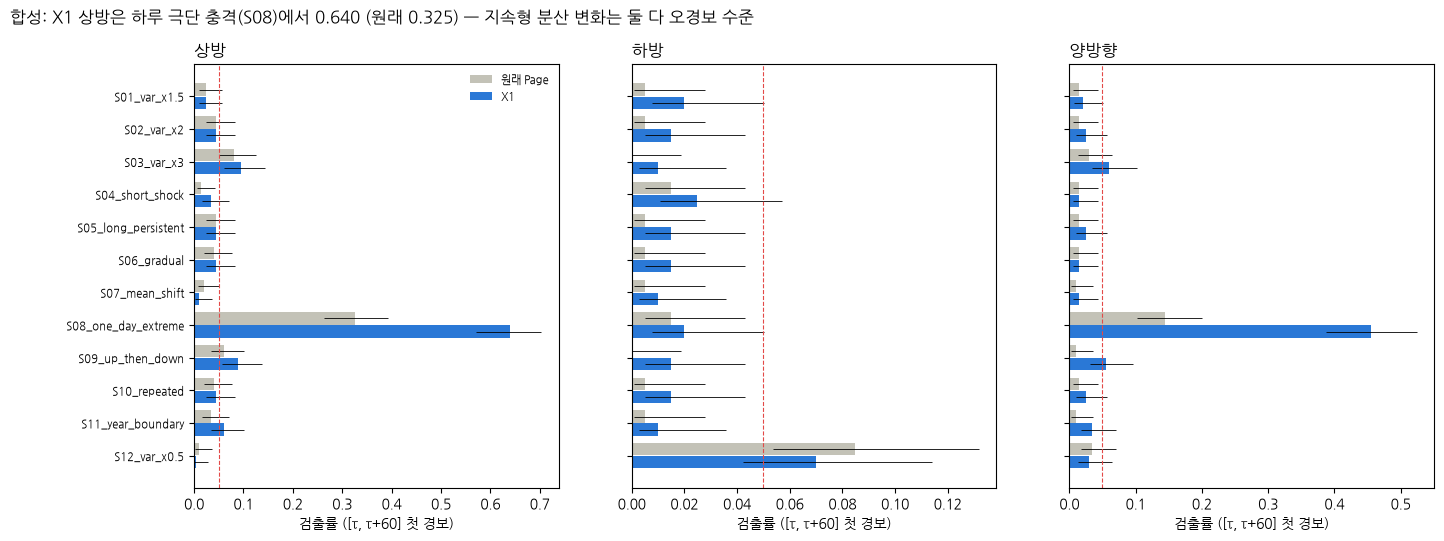

,detector,alpha,holdout_rate,cluster_ci_lo,cluster_ci_hi,size_ok_cluster,size_verdict
28,page_up,0.05,0.0440,0.0368,0.0516,True,OK
29,page_up,0.20,0.1952,0.1812,0.2096,True,OK
30,page_down,0.05,0.0672,0.0540,0.0812,False,CALIBRATION_FAIL
31,page_down,0.20,0.2040,0.1828,0.2252,True,OK
32,page_two,0.05,0.0576,0.0456,0.0700,True,OK
33,page_two,0.20,0.2176,0.1988,0.2364,True,CALIBRATION_FAIL_WILSON_ONLY
902,page_up_sn,0.05,0.0664,0.0572,0.0760,False,CALIBRATION_FAIL
903,page_up_sn,0.20,0.2024,0.1868,0.2184,True,OK
904,page_down_sn,0.05,0.0596,0.0504,0.0696,False,CALIBRATION_FAIL
905,page_down_sn,0.20,0.2152,0.1980,0.2328,True,OK


In [9]:
# 그림 X05 — 합성 검정(12번, N1 귀무 · 시나리오당 200 경로 · α=0.05): X1 이 원래 Page 보다 잘 잡는 것과 못 잡는 것.
s = SYN[(SYN["svr"] == "B1") & (SYN["reset"] == "none") & (SYN["alpha"] == 0.05) & SYN["detector"].str.startswith("page")]  # B1 · 초기화 없음 · Page 계열
scen = [x for x in s["scenario"].unique() if x != "S00_null"]  # 변화 시나리오 12개
fig, ax = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)  # 방향 3개
for j, base in enumerate(["page_up", "page_down", "page_two"]):  # 상·하·양방향
    for k, det in enumerate([base, base + "_sn"]):  # 원래 · X1
        g = s[s["detector"] == det].set_index("scenario").reindex(scen)  # 시나리오 순서
        y = np.arange(len(scen)) + (0.2 if k else -0.2)  # 막대 위치
        ax[j].barh(y, g["detection_rate"], height=0.38, color="#2a78d6" if k else "#c3c2b7", label="X1" if k else "원래 Page")  # 검출률
        ax[j].errorbar(g["detection_rate"], y, xerr=[g["detection_rate"] - g["det_ci_lo"], g["det_ci_hi"] - g["detection_rate"]], fmt="none", color="k", lw=0.6)  # 95% 구간
    ax[j].axvline(0.05, color="#e34948", lw=0.8, ls="--")  # 명목 오경보 수준
    ax[j].set_title({"page_up": "상방", "page_down": "하방", "page_two": "양방향"}[base], loc="left")  # 방향
    ax[j].set_xlabel("검출률 ([τ, τ+60] 첫 경보)")  # 축 이름
ax[0].set_yticks(range(len(scen)), scen, fontsize=8)  # 시나리오 이름
ax[0].invert_yaxis()  # 위에서부터
ax[0].legend(fontsize=8, frameon=False)  # 범례
fig.suptitle("합성: X1 상방은 하루 극단 충격(S08)에서 0.640 (원래 0.325) — 지속형 분산 변화는 둘 다 오경보 수준", x=0.01, ha="left", fontsize=12)  # 제목
show(fig, "X05_합성_검출률")  # 저장·표시
h = HOLD[(HOLD["svr"] == "B1") & HOLD["detector"].isin(["page_up", "page_down", "page_two", "page_up_sn", "page_down_sn", "page_two_sn"]) & (HOLD["reset"] == "none")]  # 홀드아웃 크기
display(h[["detector", "alpha", "holdout_rate", "cluster_ci_lo", "cluster_ci_hi", "size_ok_cluster", "size_verdict"]].round(4))  # 오경보율 검증

## 7. 실제 시장에서 X1 이 주는 정보 (12B 정렬 결과)

- 원래 Page 상방과의 공통일 순위 상관 −0.25: **다른 정보**다. 원래 Page 상방이 높은 날 상당수는 표류 때문이다.
- 연환산 20일 수준과의 상관이 0.58 → 0.26 으로 줄어든다. X1 은 수준이 아니라 *변화*에 가깝다 (5일 변화율과 ρ 0.31).
- X1 하방은 변동성이 오를 때 같은 날 떨어진다 (시차 0 ρ −0.45).
- 미래 20일 실현변동성 예측에서 하방·양방향은 정보를 더하고 상방은 더하지 않는다. 정책마다 유효일이 달라 공통 846일 수치를 함께 본다.
- X1 3종은 각각 단일 값 군집 — 다른 463 정책 어느 것과도 ρ ≥ 0.9 로 묶이지 않는다.

In [10]:
# 시장 반응 요약 (12B 결과표): X1 3종 vs 부모 Page — 연환산변동성 수준·변화 상관, 국면 대비, 시차 0 상관, 증분 정보, 값 군집.
ids = ["E3_page_up", "X1_page_up_sn", "E3_page_down", "X1_page_down_sn", "E3_page_two", "X1_page_two_sn"]  # 비교 대상
v = T["annualized_volatility_response.csv"].set_index("experiment_id").loc[ids, ["rho_vol20", "rho_d5", "rho_d20", "contrast_EXPANDING_minus_STABLE", "contrast_CONTRACTING_minus_STABLE", "contrast_HIGHEXT_STABLE_minus_LOWMID_STABLE"]]  # 국면 반응
ll = T["lead_lag_peak.csv"].set_index("experiment_id").loc[ids, ["rho_lag0", "peak_lag"]]  # 시차
fi = T["feature_incremental_information.csv"].query("scale=='past_pct' and ~exclude_2020_train").set_index("experiment_id").loc[ids, ["n_common", "rel_mse_gain_pooled", "years_positive"]]  # 증분 정보
fc = T["feature_incremental_information_common_days.csv"].query("~exclude_2020_train").set_index("feature").reindex(ids)[["rel_mse_gain_pooled"]].rename(columns={"rel_mse_gain_pooled": "rel_mse_공통846일"})  # 공통일
cl = T["agreement_clusters.csv"].set_index("experiment_id").loc[ids, ["value_cluster", "value_cluster_size"]]  # 군집
display(pd.concat([v, ll, fi, fc, cl], axis=1).round(3))  # 한 표로
o = T["ofat_pair_comparison.csv"].set_index("child").loc[["X1_page_up_sn", "X1_page_down_sn", "X1_page_two_sn"], ["parent", "common_valid_days", "raw_spearman", "pct_diff_mean_expanding", "pct_diff_mean_contracting", "alarm_days_parent", "alarm_days_child"]]  # 부모 대비
display(o.round(3))  # 부모–자식 비교

,rho_vol20,rho_d5,rho_d20,contrast_EXPANDING_minus_STABLE,contrast_CONTRACTING_minus_STABLE,contrast_HIGHEXT_STABLE_minus_LOWMID_STABLE,rho_lag0,peak_lag,n_common,rel_mse_gain_pooled,years_positive,rel_mse_공통846일,value_cluster,value_cluster_size
E3_page_up,0.578,0.153,0.158,0.195,0.057,0.254,0.444,0.0,1333,0.020,3.0,-0.086,4,23
X1_page_up_sn,0.262,0.312,0.230,0.119,-0.049,0.147,0.346,0.0,1153,-0.011,3.0,-0.012,73,1
E3_page_down,-0.106,-0.259,-0.049,-0.024,0.050,-0.025,-0.455,0.0,1333,0.035,4.0,0.022,2,107
X1_page_down_sn,-0.376,-0.235,-0.116,-0.068,0.059,-0.177,-0.453,0.0,1153,0.038,3.0,0.045,71,1
E3_page_two,0.578,0.153,0.158,0.195,0.057,0.254,0.444,0.0,1333,0.020,3.0,-0.086,4,23
X1_page_two_sn,-0.271,-0.081,-0.029,0.008,0.067,-0.121,-0.149,0.0,1153,0.081,3.0,0.027,72,1


,parent,common_valid_days,raw_spearman,pct_diff_mean_expanding,pct_diff_mean_contracting,alarm_days_parent,alarm_days_child
child,,,,,,,
X1_page_up_sn,E3_page_up,1293,-0.247,0.172,0.134,2,0
X1_page_down_sn,E3_page_down,1293,0.499,-0.048,0.008,1,4
X1_page_two_sn,E3_page_two,1293,0.577,0.004,0.192,1,3


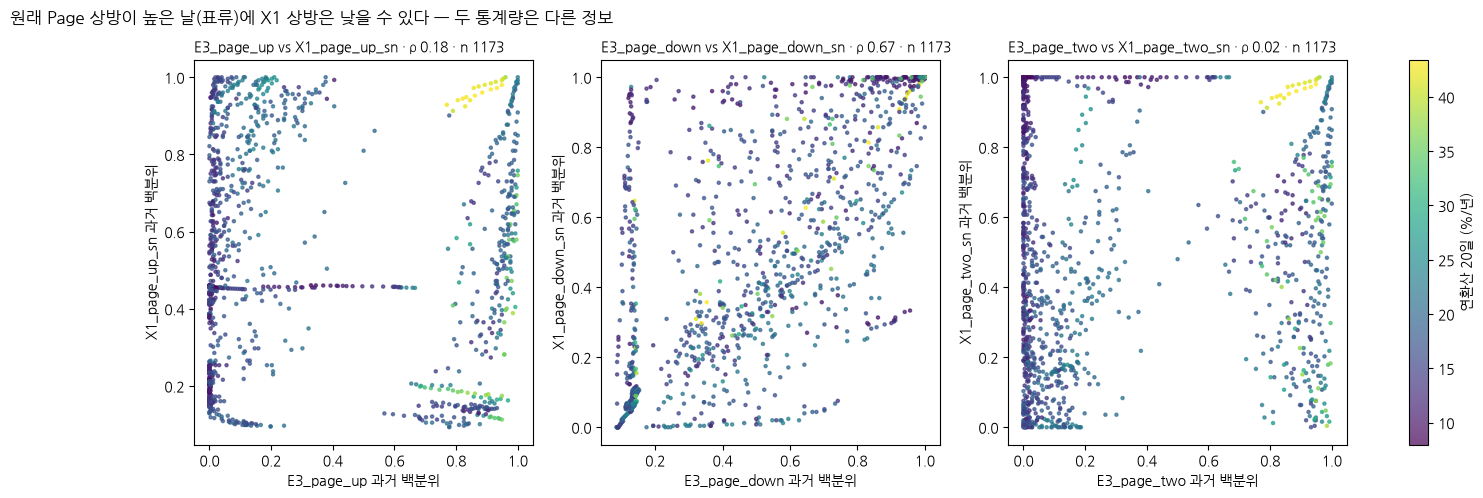

In [11]:
# 그림 X06 — 원래 Page 와 X1 의 과거 전용 백분위 산점도 (2021–2025, 같은 날): 같은 정보인가?
AL = pd.read_parquet(OUT / "policy_market_aligned.parquet", columns=["experiment_id", "date", "T_past_pct", "annualized_vol_20"])  # 정렬 원장 일부
P = AL.pivot(index="date", columns="experiment_id", values="T_past_pct")  # 날짜 × 실험
V = AL[AL["experiment_id"] == "B1"].set_index("date")["annualized_vol_20"]  # 연환산 20일
fig, ax = plt.subplots(1, 3, figsize=(16, 5))  # 방향 3개
for j, (a, b) in enumerate([("E3_page_up", "X1_page_up_sn"), ("E3_page_down", "X1_page_down_sn"), ("E3_page_two", "X1_page_two_sn")]):  # 쌍마다
    m = P[[a, b]].dropna()  # 둘 다 유효한 날
    sc = ax[j].scatter(m[a], m[b], c=V.reindex(m.index), cmap="viridis", s=5, alpha=0.7)  # 색 = 연환산 20일
    rho = m[a].rank().corr(m[b].rank())  # 순위 상관
    ax[j].set_title(f"{a} vs {b} · ρ {rho:.2f} · n {len(m)}", loc="left", fontsize=10)  # 제목
    ax[j].set_xlabel(f"{a} 과거 백분위")  # 축 이름
    ax[j].set_ylabel(f"{b} 과거 백분위")  # 축 이름
fig.colorbar(sc, ax=ax, fraction=0.02, label="연환산 20일 (%/년)")  # 색 막대
fig.suptitle("원래 Page 상방이 높은 날(표류)에 X1 상방은 낮을 수 있다 — 두 통계량은 다른 정보", x=0.01, ha="left", fontsize=12)  # 제목
show(fig, "X06_Page_vs_X1_산점도")  # 저장·표시

## 8. 판정과 다음 단계

**채택하지 않는 것**: X1 경보를 급변 신호로 쓰는 것. 실데이터 2021–2025 상방 0회, 오경보율 보정 실패, 결과를 본 뒤 추가된 탐색 통계량이다.

**남기는 것**: X1 하방·양방향 상태를 Autoencoder 의 연속 피처 후보로 둔다 (다른 정책과 독립 군집, 증분 정보 양수). 단, 2020-09-21 이전은 NA 이고 마스크와 함께 넘긴다.

**다음 실험 (사전 등록 필요)**
1. 다른 ETF(코스닥·나스닥·채권)와 2026 이후 자료에서 같은 X1 정의를 맹검 검증
2. X1w 처럼 학습 표본내 잔차로 기준창을 채우는 변형을 귀무 MC 로 정식 보정 (COVID 같은 초기 구간 관측)
3. 고정일(커널 소실) v^ 를 대체한 반사실 잔차로 X1 을 다시 계산해 2020 반응 분리
4. 기준창 지연 21·61·126일의 합성 검출력 비교 (현재는 원시 상태 탐색만)

특집 그림 6장: `research/k200_cusum_overlay_12b/figures_x1/` · 전체 결과: `12B_최종보고_KODEX200_CUSUM_시장정렬.ipynb`

In [12]:
# 마지막 검사: 본문 수치를 결과 파일·이 노트북 계산과 대조하고, 12번 보호 파일이 그대로인지 확인한다.
claims = {}  # 설명 → (계산값, 기대값)
claims["X1 첫 유효일"] = (CHK["x1_first_valid"], "2020-09-21")  # 기준 유효 120일
claims["X1 상방 경보"] = (int(X1D["X1_up_alarm_a05"].sum()), 0)  # 경보 수 (α=0.05)
claims["X1 하방 경보"] = (int(X1D["X1_down_alarm_a05"].sum()), 4)  # 경보 수 (α=0.05)
claims["X1 양방향 경보"] = (int(X1D["X1_two_alarm_a05"].sum()), 3)  # 경보 수 (α=0.05)
claims["X1w 상방 첫 경보"] = (str(X1D.loc[X1D["X1w_up_alarm_a05_REFERENCE"].astype(bool), "date"].min().date()), "2020-03-18")  # 참조
claims["상방 증분 경계 e²"] = (round(thr, 3), 1.386)  # 경계 2 ln2
claims["2024 연평균 e²"] = (round(float(tab.loc[2024, "연평균 e²"]), 2), 1.46)  # 표류 원인
claims["2025 연평균 e²"] = (round(float(tab.loc[2025, "연평균 e²"]), 2), 1.57)  # 표류 원인
claims["S08 X1 상방 검출률"] = (float(s.query("detector=='page_up_sn' and scenario=='S08_one_day_extreme'")["detection_rate"].iloc[0]), 0.64)  # 합성
claims["S12 X1 하방 검출률"] = (float(s.query("detector=='page_down_sn' and scenario=='S12_var_x0.5'")["detection_rate"].iloc[0]), 0.07)  # 분산 감소
claims["S12 원래 하방 검출률"] = (float(s.query("detector=='page_down' and scenario=='S12_var_x0.5'")["detection_rate"].iloc[0]), 0.085)  # 분산 감소
claims["S08 원래 상방 검출률"] = (float(s.query("detector=='page_up' and scenario=='S08_one_day_extreme'")["detection_rate"].iloc[0]), 0.325)  # 합성
claims["X1 상방 홀드아웃 α=0.05"] = (round(float(h.query("detector=='page_up_sn' and alpha==0.05")["holdout_rate"].iloc[0]), 4), 0.0664)  # 크기
claims["X1 상방 수준 ρ"] = (round(float(v.loc["X1_page_up_sn", "rho_vol20"]), 3), 0.262)  # 시장 반응
claims["Page 상방 수준 ρ"] = (round(float(v.loc["E3_page_up", "rho_vol20"]), 3), 0.578)  # 시장 반응
claims["X1 상방 vs Page 상방 ρ"] = (round(float(o.loc["X1_page_up_sn", "raw_spearman"]), 3), -0.247)  # 다른 정보
claims["2024-08-05 기본 e~"] = (round(float(sens.loc["기본 [t-252, t-61] · 120", "2024-08-05 e~"]), 2), -3.77)  # 충격일
claims["COVID 기준창 기간 안 하방 경보"] = (int(sum(pd.Timestamp(first_in) <= x <= pd.Timestamp(last_in) for x in X1D.loc[X1D["X1_down_alarm_a05"].astype(bool), "date"])), 3)  # 하방 경보 4회 중
bad = {k: v for k, v in claims.items() if v[0] != v[1]}  # 불일치
print(f"X1 특집 CLAIMS {len(claims) - len(bad)}/{len(claims)} 일치 · 저장 그림 {len(SAVED)}장 → {FX.relative_to(ROOT)}")  # 결과
assert not bad, bad  # 불일치면 실패
bad_p = [p for hh, p in PROT if sha(ROOT / p) != hh]  # 12번 보호 파일
assert not bad_p, bad_p  # 변경 금지

X1 특집 CLAIMS 18/18 일치 · 저장 그림 6장 → research/k200_cusum_overlay_12b/figures_x1
